In [ ]:
import scanpy as sc
import scanpy.external as sce

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad

from copy import deepcopy

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

import chronopack as cp

# Create AnnData object

In [2]:
sample_paths = [
    '../input/N701_scK562_TNFA_Replication_RT_1.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N702_scK562_TNFA_Replication_RT_2.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N703_scK562_TNFA_Replication_RT_3.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N704_scK562_TNFA_Replication_RT_4.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
]

adata = cp.io.read_time_tagged_dge(sample_paths, sample_names=['N701', 'N702', 'N703', 'N704'])
print(adata)

AnnData object with n_obs × n_vars = 7646 × 27942
    obs: 'COUNTS', 'sample', 'time', 'time_group'
    uns: 'chronopack'


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/anndata/utils.py:311: UserWarning: X converted to numpy array with dtype float64
  warnings.warn(f"{name} converted to numpy array with dtype {arr.dtype}")


# QC & preprocessing

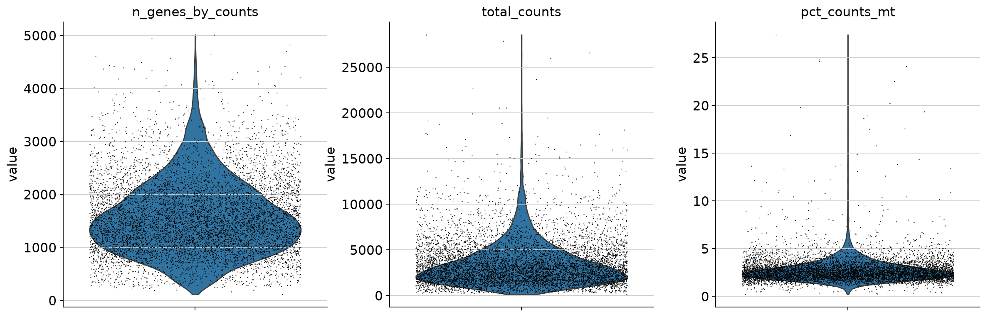

filtered out 7906 genes that are detected in less than 3 cells
AnnData object with n_obs × n_vars = 7164 × 20036
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'chronopack'


In [3]:
cp.io.annotate_qc_metrics(adata)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

adata = cp.io.filter_cells_by_qc(adata, min_counts=500, max_counts=15000, max_pct_mt=5, min_genes=500)
sc.pp.filter_genes(adata, min_cells=3)
print(adata)

In [4]:
sc.pp.scrublet(adata, batch_key="sample")
adata = adata[~adata.obs['predicted_doublet'], :]

Running Scrublet
filtered out 4726 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.34
Detected doublet rate = 0.3%
Estimated detectable doublet fraction = 0.9%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 36.4%
filtered out 5507 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata

# Standard processing

In [5]:
cell_cycle_genes = [x.strip() for x in open('/new-stg/home/alex/ref/gene_sets/regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
cell_cycle_genes = [x for x in cell_cycle_genes if x in adata.var_names]


In [6]:
cp.io.initialize_expression_layers(adata, target_sum=1e4)

sc.pp.highly_variable_genes(adata, batch_key='sample', n_top_genes=3000)
sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
adata_hvg = adata[:, adata.var.highly_variable]
bck = adata_hvg.copy()

/new-stg/home/alex/tmp/ChronoPack/src/chronopack/io/_preprocessing.py:296: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  out.layers[counts_layer] = out.X.copy()


normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:02)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
calculating cell cycle phase
computing score 'S_score'
    finished: added
    'S_score', score of gene set (adata.obs).
    341 total control genes are used. (0:00:00)
computing score 'G2M_score'
    finished: added
    'G2M_score', score of gene set (adata.obs).
    425 total control genes are used. (0:00:00)
-->     'phase', cell cycle phase (adata.obs)


regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


    finished (0:00:01)
computing PCA
    with n_comps=50
    finished (0:00:08)


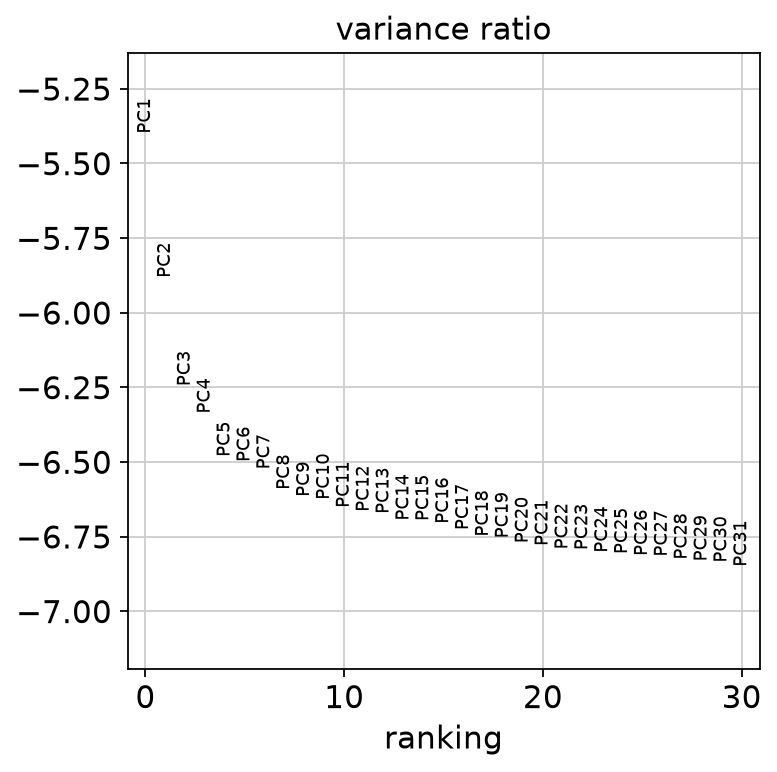

computing neighbors
    using 'X_pca' with n_pcs = 12


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:09)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:16)
running Leiden clustering


/new-stg/home/alex/.tmp/ipykernel_3985054/2110161163.py:8: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_hvg, resolution=0.1, key_added='leiden_unintegrated')


    finished: found 1 clusters and added
    'leiden_unintegrated', the cluster labels (adata.obs, categorical) (0:00:01)


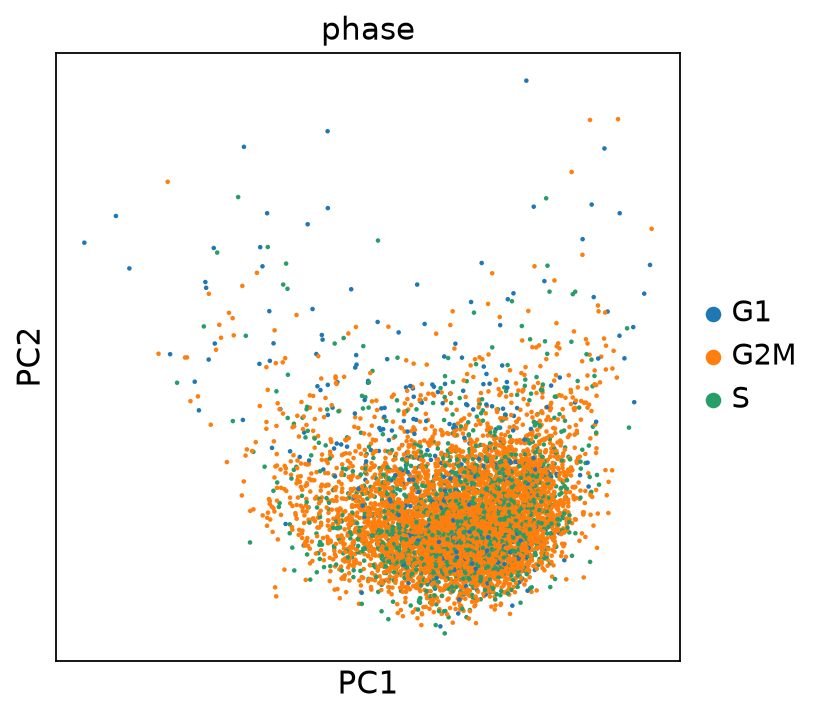

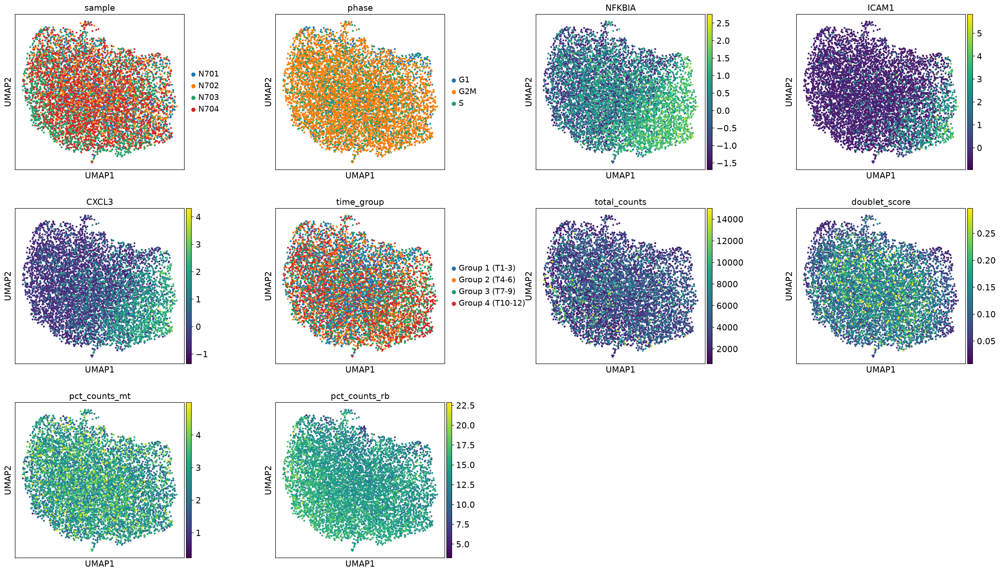

In [7]:
sc.pp.regress_out(adata_hvg, ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score'])
sc.pp.scale(adata_hvg)
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=30, log=True)
sc.pp.neighbors(adata_hvg, n_pcs=12)

sc.tl.umap(adata_hvg)
sc.tl.leiden(adata_hvg, resolution=0.1, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata_hvg, color='phase')
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb'], wspace=0.4, size=40, ncols=4)

# Batch effect correction w/ComBat

In [8]:
df = adata.obs[['time', 'sample']]
table = pd.crosstab(df['time'], df['sample'])
print(table)


sample  N701  N702  N703  N704
time                          
1        189   157   164   166
2        199   180   174   148
3        131   112   113   126
4        139   163   139   152
5        134    93   127   108
6        100   113    98   106
7        201   190   215   190
8        165   166   165   143
9        136   130   123   129
10       152   176   162   131
11       134   142   172   166
12       166   146   145   155


regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']
    finished (0:00:00)
Standardizing Data across genes.

Found 4 batches

Found 0 numerical variables:
	

Fitting L/S model and finding priors

Finding parametric adjustments

Adjusting data

computing PCA
    with n_comps=50
    finished (0:00:10)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:16)


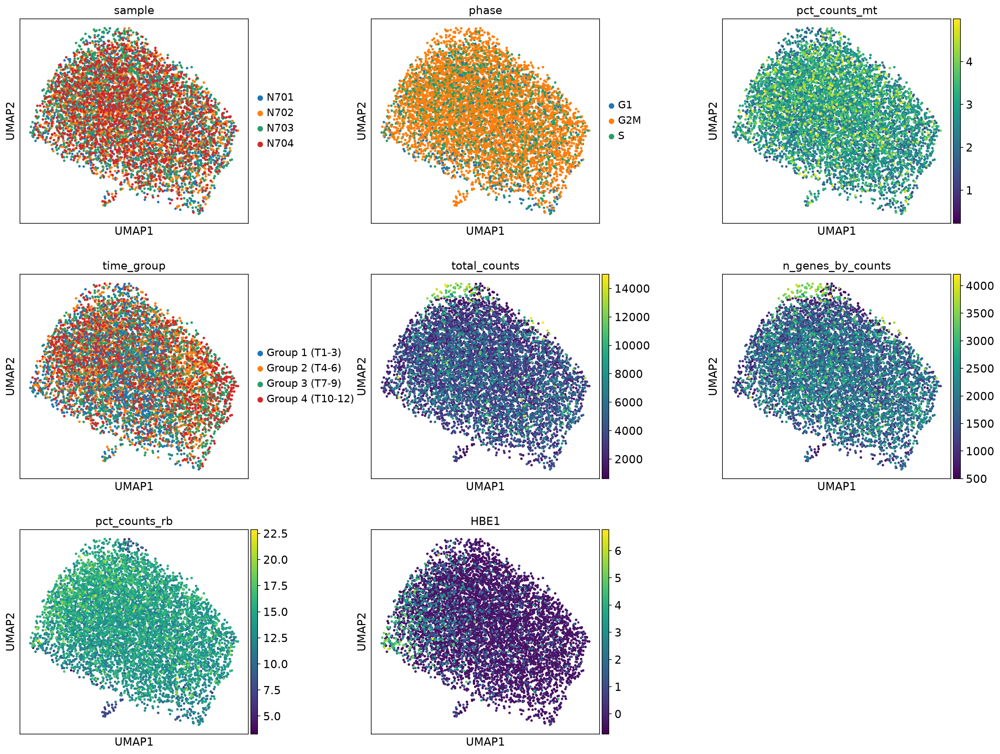

In [9]:
adata_hvg = bck.copy()

sc.pp.regress_out(adata_hvg, keys=['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']) # Remove QC + cell-cycle effects first
sc.pp.combat(adata_hvg, key='sample') # Batch correction on (log1p + residual) expression
adata_hvg.layers['corrected'] = adata_hvg.X.copy()

sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50)
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_hvg)
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'pct_counts_mt', 'time_group', 'total_counts', 'n_genes_by_counts', 'pct_counts_rb', 'HBE1'], wspace=0.4, size=40, ncols=3)


running Leiden clustering
    finished: found 4 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:03)


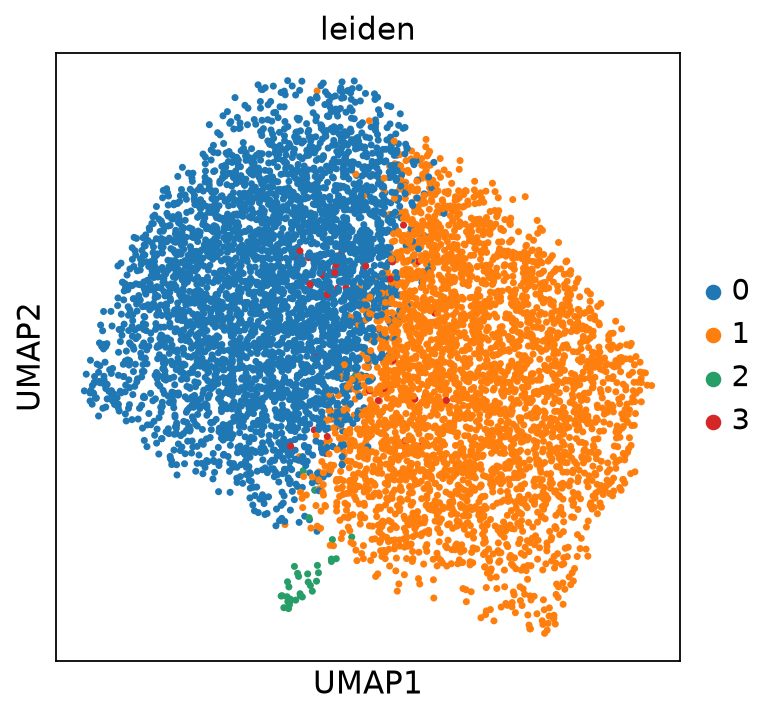

In [10]:
sc.tl.leiden(adata_hvg, resolution=0.5)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)

Next, we'll iteratively remove clusters corresponding to low-quality cells

running Leiden clustering


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/scanpy/tools/_leiden.py:198: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_added] = pd.Categorical(


    finished: found 5 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:04)


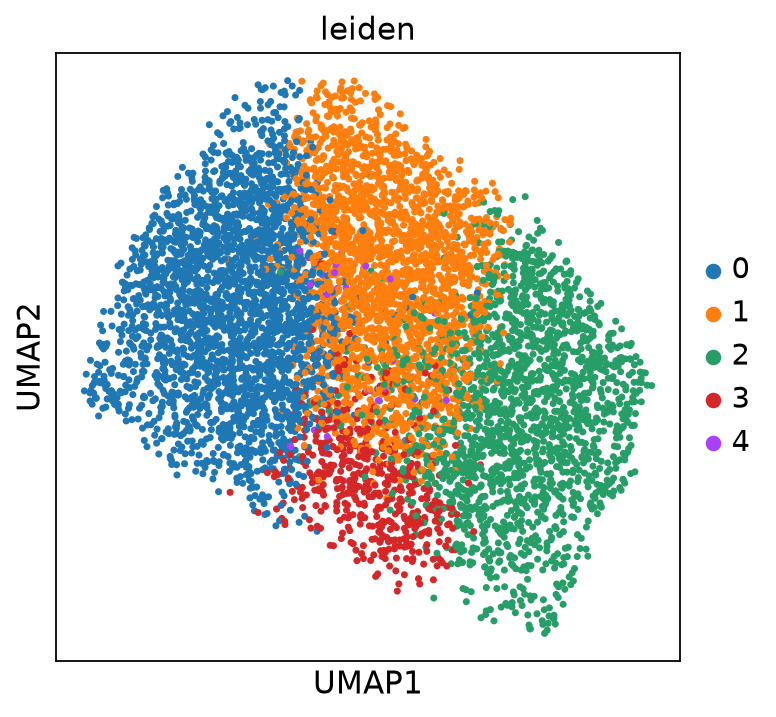

In [11]:
adata_hvg = adata_hvg[adata_hvg.obs['leiden'] != '2', :]
sc.tl.leiden(adata_hvg, resolution=0.7)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)

running Leiden clustering
    finished: found 10 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:07)


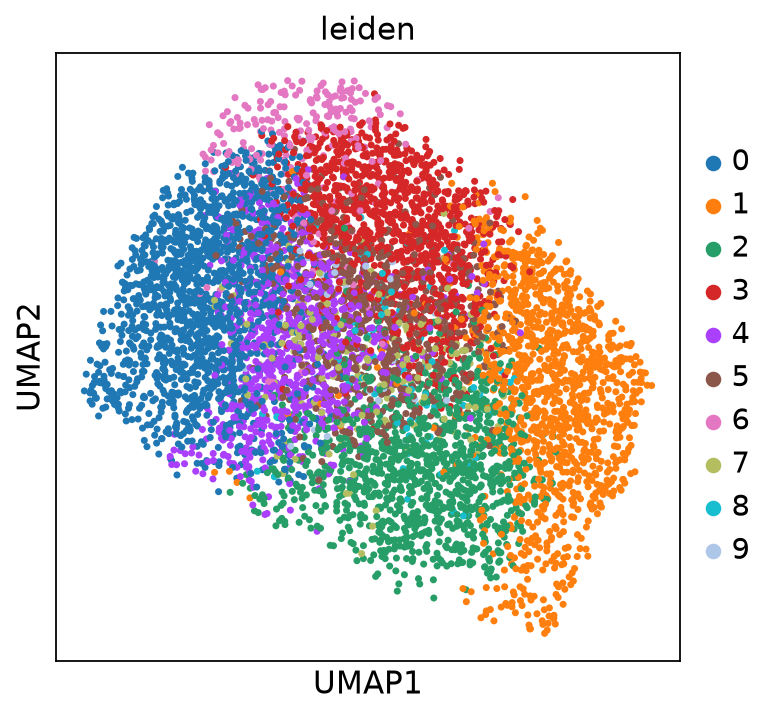

In [12]:
sc.tl.leiden(adata_hvg, resolution=1.0)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)

running Leiden clustering


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/scanpy/tools/_leiden.py:198: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_added] = pd.Categorical(


    finished: found 5 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:04)


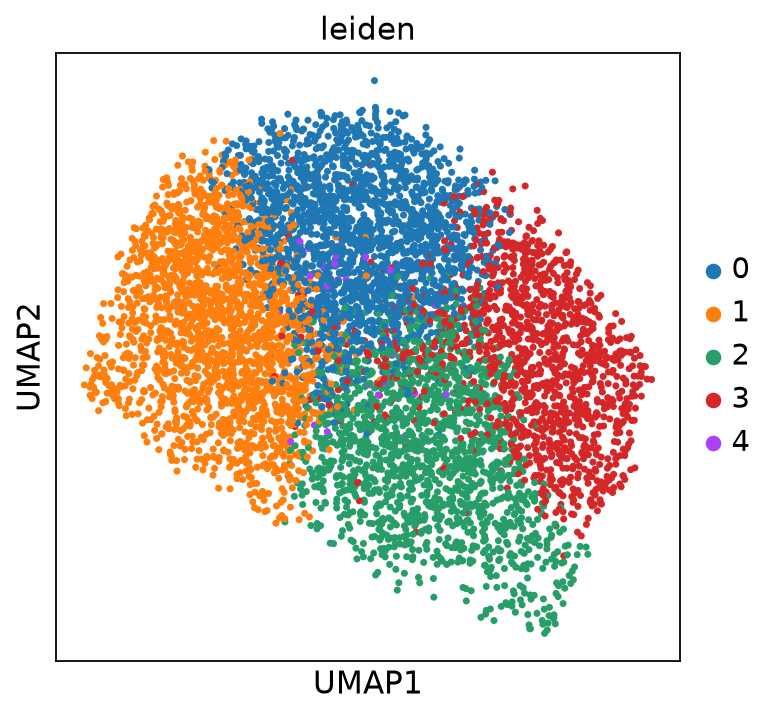

In [13]:
adata_hvg = adata_hvg[adata_hvg.obs['leiden'] != '6', :]
sc.tl.leiden(adata_hvg, resolution=0.7)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)

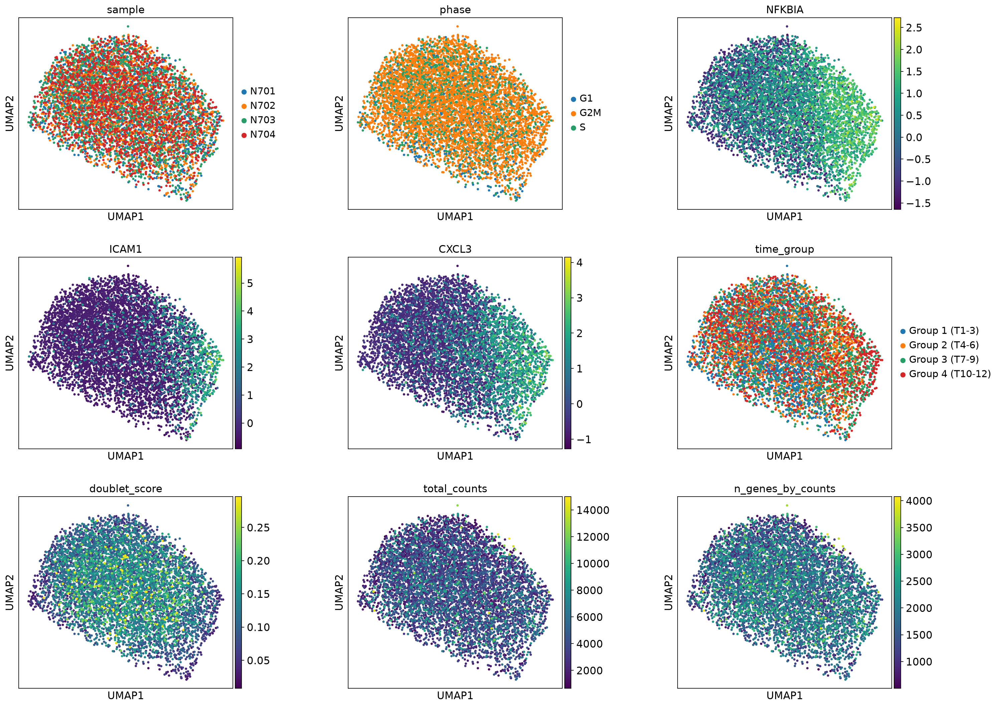

In [14]:
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'doublet_score', 'total_counts', 'n_genes_by_counts'], wspace=0.4, size=40, ncols=3)

In [17]:
adata = adata[adata_hvg.obs.index, :]
adata.obsp = adata_hvg.obsp.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obs = adata_hvg.obs.copy()

print(adata)
print(adata_hvg)

AnnData object with n_obs × n_vars = 6857 × 20036
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'chronopack', 'scrublet', 'log1p', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', 'cpm', 'log1p'
    obsp: 'distances', 'connectivities'
AnnData object with n_obs × n_vars = 6857 × 3000
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt'

# Save single-cell AnnData object

In [ ]:
cp.io.validate_preprocessed_adata(
    adata,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)
cp.io.validate_preprocessed_adata(
    adata_hvg,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)

adata.write_h5ad('../output/adata_full.1e4-variant.chk0.h5ad')
adata_hvg.write_h5ad('../output/adata_hvg.1e4-variant.chk0.h5ad')
